# plate_defect_count 포함 vs 제외 — 최종 Soft Voting 비교
- **포함:** 최종 모델 그대로 (36개 피처, 06번에서 튜닝한 파라미터)
- **제외:** plate_defect_count만 뺀 35개 피처로 ExtraTrees·RF·GBM을 **06번과 같은 탐색 공간·횟수로 다시 튜닝** 후 Soft Voting
- **비교:** 같은 5-fold(팀 공통 CV)와 같은 반복 CV(5×3, 15 fold). Test 미사용
- `RERUN = False`면 저장된 결과(`results/ablation/`)를 불러옴. 처음 실행은 수 분~십여 분 소요

In [1]:
import sys, warnings, pickle, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

from config import RANDOM_STATE, CV
from load_data import load_data
from Taegyeom_model_utils import (CLASS_ORDER, PLATE_KEYS, build_preprocessor, discrete_indices, over_strategy,
                                  BalancedWeightClassifier, add_features, PlateContextEncoder)
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.metrics import f1_score
from sklearn.model_selection import RandomizedSearchCV, RepeatedStratifiedKFold
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from joblib import Parallel, delayed

OUT = ROOT / "results" / "ablation"; OUT.mkdir(parents=True, exist_ok=True)
RERUN = False                                             # True: 튜닝·CV 다시 계산
CACHE = OUT / "Taegyeom_ablation_plate_count_cache.pkl"
cache = pickle.load(open(CACHE, "rb")) if (CACHE.exists() and not RERUN) else {}
def cached(key, fn):
    if key not in cache:
        cache[key] = fn(); pickle.dump(cache, open(CACHE, "wb"))
    return cache[key]

for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK TC"]:
    if any(f == x.name for x in mpl.font_manager.fontManager.ttflist):
        mpl.rcParams["font.family"] = f; break
mpl.rcParams.update({"axes.unicode_minus": False, "figure.dpi": 100})
pd.set_option("display.width", 220)

In [2]:
X_train, _, y_train, _ = load_data()                     # Train만 사용
RS = RANDOM_STATE
XF = add_features(X_train)                               # 행 단위 파생변수 8개 → 34열

class PlateContextNoCount(TransformerMixin, BaseEstimator):
    # 강판 맥락 변수 중 thickness_per_conveyer만 생성 (plate_defect_count 제외)
    def fit(self, X, y=None): return self
    def transform(self, X):
        out = X.copy(); out["thickness_per_conveyer"] = X["Steel_Plate_Thickness"] / X["Length_of_Conveyer"]; return out

SETTINGS = {   # 설정 이름: (강판 맥락 인코더, 모델 입력 피처)
    "포함 (36개)": (PlateContextEncoder, list(XF.columns) + ["plate_defect_count", "thickness_per_conveyer"]),
    "제외 (35개)": (PlateContextNoCount, list(XF.columns) + ["thickness_per_conveyer"]),
}
def pipe(setting, model, sampler="passthrough"):
    enc, feats = SETTINGS[setting]
    return ImbPipeline([("plate", enc()), ("prep", build_preprocessor(feats)), ("sampler", sampler), ("model", model)])
for s, (_, f) in SETTINGS.items(): print(s, len(f), "개 피처")

포함 (36개) 36 개 피처
제외 (35개) 35 개 피처


## 1. 제외 설정 재튜닝 (06번과 같은 탐색 공간·횟수·난수)

In [3]:
def search_spec(setting):
    smote = lambda: SMOTENC(categorical_features=discrete_indices(SETTINGS[setting][1]), sampling_strategy=over_strategy(1), k_neighbors=5, random_state=RS)
    GP = "model__estimator__"
    return {
        "ExtraTrees": dict(n_iter=15, pipe=pipe(setting, ExtraTreesClassifier(random_state=RS, n_jobs=1), smote()),
            space={"sampler": [smote(), "passthrough"], "model__class_weight": [None, "balanced", "balanced_subsample"],
                   "model__n_estimators": randint(300, 900), "model__max_depth": [None, 15, 25], "model__min_samples_leaf": randint(1, 5),
                   "model__max_features": ["sqrt", 0.3, 0.5, 0.7]}),
        "Random Forest": dict(n_iter=12, pipe=pipe(setting, RandomForestClassifier(random_state=RS, n_jobs=1), smote()),
            space={"sampler": [smote(), "passthrough"], "model__class_weight": [None, "balanced_subsample"],
                   "model__n_estimators": randint(300, 700), "model__max_depth": [None, 15, 25], "model__min_samples_leaf": randint(1, 5),
                   "model__max_features": ["sqrt", 0.3, 0.5]}),
        "GBM": dict(n_iter=8, pipe=pipe(setting, BalancedWeightClassifier(GradientBoostingClassifier(random_state=RS), alpha=1)),
            space={"model__alpha": [0.5, 1], GP + "n_estimators": randint(100, 350), GP + "learning_rate": loguniform(0.03, 0.2),
                   GP + "max_depth": randint(3, 6), GP + "subsample": uniform(0.6, 0.4), GP + "max_features": [None, "sqrt", 0.5],
                   GP + "min_samples_leaf": randint(1, 10)}),
    }
MEMBERS = ["ExtraTrees", "Random Forest", "GBM"]
SPEC = {s: search_spec(s) for s in SETTINGS}

def do_search(name):   # 제외 설정만 새로 튜닝 (5-fold, Macro F1)
    sp = SPEC["제외 (35개)"][name]
    rs = RandomizedSearchCV(sp["pipe"], sp["space"], n_iter=sp["n_iter"], scoring="f1_macro", cv=CV, n_jobs=-1,
                            random_state=RS + 7, refit=False)
    rs.fit(XF, y_train); return pd.DataFrame(rs.cv_results_)

best = lambda r: r.loc[r["rank_test_score"].idxmin()]
ens = pickle.load(open(ROOT / "results/ensemble/Taegyeom_ensemble_cache.pkl", "rb"))   # 포함 설정: 06번 튜닝 결과 그대로
PARAMS = {"포함 (36개)": {n: best(ens[("search", n)])["params"] for n in MEMBERS}, "제외 (35개)": {}}
rows = []
t0 = time.perf_counter()
for n in MEMBERS:
    r = cached(("search", n), lambda n=n: do_search(n)); PARAMS["제외 (35개)"][n] = best(r)["params"]
    rows.append({"모델": n, "포함 (36개) 튜닝 최고": best(ens[("search", n)])["mean_test_score"], "제외 (35개) 재튜닝 최고": best(r)["mean_test_score"]})
print(f"튜닝 소요 {time.perf_counter() - t0:.0f}초")
display(pd.DataFrame(rows).set_index("모델").round(4))   # 구성 모델별 단일 5-fold 최고값
for n in MEMBERS:
    print(f"[제외] {n:14s}", {k.split("__")[-1]: (round(v, 4) if isinstance(v, float) else v) for k, v in PARAMS["제외 (35개)"][n].items()
                               if k != "sampler"}, "| 샘플러:", "SMOTENC" if not isinstance(PARAMS["제외 (35개)"][n].get("sampler", "passthrough"), str) else "없음")

튜닝 소요 44초


,포함 (36개) 튜닝 최고,제외 (35개) 재튜닝 최고
모델,,
ExtraTrees,0.8180,0.8162
Random Forest,0.8125,0.8125
GBM,0.8401,0.8348


[제외] ExtraTrees     {'class_weight': 'balanced_subsample', 'max_depth': 15, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 699} | 샘플러: SMOTENC
[제외] Random Forest  {'class_weight': None, 'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 1, 'n_estimators': 483} | 샘플러: 없음
[제외] GBM            {'alpha': 1, 'learning_rate': np.float64(0.1704), 'max_depth': 4, 'max_features': 0.5, 'min_samples_leaf': 5, 'n_estimators': 243, 'subsample': np.float64(0.921)} | 샘플러: 없음


## 2. 같은 분할에서 Soft Voting 비교 (5-fold + 반복 CV 15 fold)

In [7]:
def member(setting, name):   # 설정별 튜닝 파라미터를 적용한 구성 모델
    return clone(SPEC[setting][name]["pipe"]).set_params(**PARAMS[setting][name])

SPLITS = {"5-fold": list(CV.split(XF, y_train)),
          "반복 CV(5×3)": list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RS).split(XF, y_train))}

def fold_proba(setting, name, cv, i):   # fold 하나에서 구성 모델 1개 학습 → 검증 fold 확률
    tr, va = SPLITS[cv][i]
    m = member(setting, name); m.fit(XF.iloc[tr], y_train.iloc[tr])
    return setting, name, cv, i, pd.DataFrame(m.predict_proba(XF.iloc[va]), columns=m.classes_)[CLASS_ORDER].values

def run_all():
    jobs = [(s, n, cv, i) for s in SETTINGS for n in MEMBERS for cv in SPLITS for i in range(len(SPLITS[cv]))]
    return {(s, n, cv, i): p for s, n, cv, i, p in Parallel(n_jobs=-1)(delayed(fold_proba)(*j) for j in jobs)}
t0 = time.perf_counter(); PROBA = cached("fold_proba", run_all); print(f"CV 소요 {time.perf_counter() - t0:.0f}초")

CLS = np.array(CLASS_ORDER)
def sv_scores(setting, cv):   # Soft Voting = 3개 모델 확률 평균 → fold별 Macro F1과 예측
    sc, preds = [], []
    for i, (_, va) in enumerate(SPLITS[cv]):
        pred = CLS[np.mean([PROBA[(setting, n, cv, i)] for n in MEMBERS], axis=0).argmax(1)]
        sc.append(f1_score(y_train.iloc[va], pred, average="macro")); preds.append(pred)
    return np.array(sc), preds
SC = {(s, cv): sv_scores(s, cv) for s in SETTINGS for cv in SPLITS}

rows = []
for cv in SPLITS:
    inc, exc = SC[("포함 (36개)", cv)][0], SC[("제외 (35개)", cv)][0]
    rows.append({"분할": cv, "fold 수": len(inc), "포함 (36개)": inc.mean(), "포함 std": inc.std(), "제외 (35개)": exc.mean(), "제외 std": exc.std(),
                 "차이 (포함−제외)": (inc - exc).mean(), "포함이 좋은 fold": f"{(inc > exc).sum()}/{len(inc)}"})
result = pd.DataFrame(rows).set_index("분할")
result.to_csv(OUT / "Taegyeom_ablation_plate_count_cv.csv", encoding="utf-8-sig")
display(result.round(4))

CV 소요 0초


,fold 수,포함 (36개),포함 std,제외 (35개),제외 std,차이 (포함−제외),포함이 좋은 fold
분할,,,,,,,
5-fold,5,0.8441,0.0188,0.8368,0.0179,0.0073,5/5
반복 CV(5×3),15,0.8389,0.0231,0.8371,0.0232,0.0018,9/15


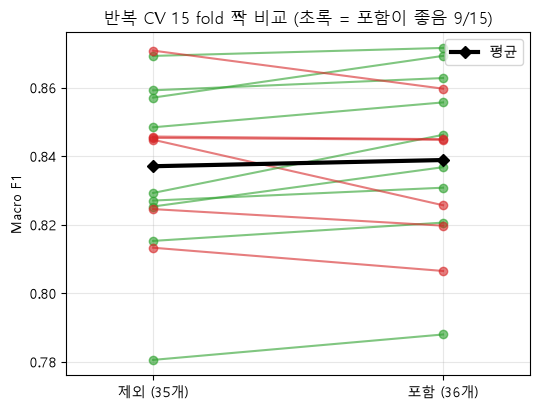

In [5]:
# fold별 짝 비교 (반복 CV 15 fold): 같은 fold끼리 선으로 연결
inc, exc = SC[("포함 (36개)", "반복 CV(5×3)")][0], SC[("제외 (35개)", "반복 CV(5×3)")][0]
fig, ax = plt.subplots(figsize=(5.5, 4.2))
for a, b in zip(exc, inc): ax.plot([0, 1], [a, b], color="tab:green" if b > a else "tab:red", alpha=0.6, marker="o")
ax.plot([0, 1], [exc.mean(), inc.mean()], color="k", lw=3, marker="D", label="평균")
ax.set_xticks([0, 1], ["제외 (35개)", "포함 (36개)"]); ax.set_xlim(-0.3, 1.3); ax.set_ylabel("Macro F1"); ax.legend()
ax.set_title(f"반복 CV 15 fold 짝 비교 (초록 = 포함이 좋음 {(inc > exc).sum()}/15)"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 3. 처음 보는 강판 조건에서의 오분류율 (반복 CV)

In [6]:
# 검증 fold의 강판 조건(컨베이어 길이·두께·강종)이 학습 fold에 없던 경우 vs 있던 경우
key = X_train[PLATE_KEYS].astype(str).agg("_".join, axis=1).values
rows = []
for s in SETTINGS:
    err = {"unseen": [0, 0], "seen": [0, 0]}
    for (tr, va), pred in zip(SPLITS["반복 CV(5×3)"], SC[(s, "반복 CV(5×3)")][1]):
        unseen = ~np.isin(key[va], key[tr]); wrong = pred != y_train.values[va]
        err["unseen"][0] += wrong[unseen].sum(); err["unseen"][1] += unseen.sum()
        err["seen"][0] += wrong[~unseen].sum(); err["seen"][1] += (~unseen).sum()
    rows.append({"설정": s, "처음 보는 조건 건수": err["unseen"][1], "처음 보는 조건 오분류율": err["unseen"][0] / err["unseen"][1],
                 "있던 조건 오분류율": err["seen"][0] / err["seen"][1]})
seen_tbl = pd.DataFrame(rows).set_index("설정")
seen_tbl.to_csv(OUT / "Taegyeom_ablation_plate_count_seen.csv", encoding="utf-8-sig")
display(seen_tbl.round(4))
# 처음 보는 조건은 plate_defect_count가 0으로 들어감 → 이 그룹에서도 포함 설정이 나쁘지 않은지 확인

,처음 보는 조건 건수,처음 보는 조건 오분류율,있던 조건 오분류율
설정,,,
포함 (36개),245,0.3347,0.1791
제외 (35개),245,0.3714,0.1793
